# Tarea 2 – Parte 2: Evaluación y extracción estructurada

**Fuentes y licencias:** este notebook reutiliza únicamente el corpus de la Parte 1. El detalle de cada archivo
(URL, licencia, procedimiento de descarga) está en `datos/fuentes.csv` y en el `README.md`.

**Regla de evaluación:** todas las configuraciones de modelos se fijan en la celda de configuración **antes**
de calcular métricas. No se ajustan parámetros mirando los resultados sobre la muestra de evaluación.

## 0. Configuración (fijada antes de ver métricas)

In [2]:
import os, re, json, time, random, unicodedata
from datetime import date
import pandas as pd
import matplotlib.pyplot as plt

os.environ["HF_HUB_DISABLE_XET"] = "1"                      # descarga clásica de Hugging Face
os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"


SEED = 42
random.seed(SEED)

# --- Rutas ---
DOCS_CSV   = "datos/documentos.csv"
AUDIO_CSV  = "datos/transcripciones.csv"
MUESTRA_CSV   = "datos/muestra_eval.csv"   # solo guarda los ids de la muestra fija
RESULTADOS_CSV = "datos/resultados_eval.csv"
EXTRACCION_CSV = "datos/extraccion_llm.csv"
AUDITORIA_CSV  = "datos/auditoria_llm.csv"

# --- Columnas obligatorias de la Parte 1 ---
DOC_ID, DOC_RUTA, DOC_TIPO, DOC_TEXTO = "id", "archivo", "tipo", "texto_ocr"
AUD_ID, AUD_RUTA, AUD_DUR, AUD_TEXTO = "id", "archivo_audio", "duracion_seg", "texto_asr"
# Columna adicional que debes agregar a transcripciones.csv para el análisis de casos difíciles:
# valores como "limpio", "ruido", "musica", "varios_hablantes", "telefono"...
AUD_COND = "condicion"

# --- Configuración de modelos (no modificar tras ver métricas) ---
OCR_BASE = {"modelo": "PaddleOCR", "lang": "es"}            # sin personalización
OCR_ALT  = {"modelo": "Tesseract", "lang": "spa", "psm": 3}
ASR_BASE = {"modelo": "faster-whisper small", "size": "small", "device": "cpu",
            "compute_type": "int8", "language": "es"}
ASR_ALT  = {"modelo": "MMS-1b-all", "hf_id": "facebook/mms-1b-all", "lang": "spa"}
LLM      = {"modelo": "qwen2.5:7b", "url": "http://localhost:11434/api/generate"}  # Ollama local

## 1. Muestra de evaluación (sin nuevos datos)
10 documentos (incluyendo los tres tipos) y 10 clips (distintas fuentes/condiciones), seleccionados con semilla fija.

In [3]:
docs = pd.read_csv(DOCS_CSV)
audio = pd.read_csv(AUDIO_CSV)
for df in (docs, audio):
    if "texto_referencia" not in df.columns:
        df["texto_referencia"] = ""
    df["texto_referencia"] = df["texto_referencia"].fillna("").astype(str)

assert AUD_COND in audio.columns, (
    "Agrega una columna 'condicion' a transcripciones.csv (limpio, ruido, musica, ...) "
    "para poder elegir clips de distintas condiciones y analizar casos difíciles.")

print(len(docs), "documentos |", len(audio), "clips |",
      round(audio[AUD_DUR].sum() / 60, 1), "min de audio")
print(docs[DOC_TIPO].value_counts(), "\n")
print(audio[AUD_COND].value_counts())

25 documentos | 22 clips | 32.2 min de audio
tipo
manuscrito    9
impreso       8
foto          8
Name: count, dtype: int64 

condicion
limpio              17
varios_hablantes     4
ruido                1
Name: count, dtype: int64


In [4]:
import soundfile as sf, librosa, glob

# Docs: doc_001, doc_002 y doc_022 se evalúan sobre un recorte (texto parcial); el resto, imagen completa
# Audios: primeros 15 s de cada clip, sin marcas de hablante y con nombres seudonimizados
referencias = {
    "doc_001": """Horarios de Atención Museo de Arte y Tradiciones Peruanas Lun-Vi 9:00 – 18:00 Museo Naval –
Casa Grau Mar-Dom 9:00 – 14:30 Centro Cultural UNMSM Lun-Vie 9:00- 17:00 Iglesia y Monasterio de Jesús
María y José Lun-Dom 09:00- 12:00/ 15:00- 17:00 Centro Cultural de la Beneficencia Lun-Dom 10:00- 19:00
Museo Andrés del Castillo Lun- Dom 09:00 18:00""",
    "doc_002": """TEMPLO DEL SOL La monumentalidad del Templo del Sol, denominado tempranamente
“Punchao Cancha” o “Recinto del día”, constituye la mayor evidencia de la trascendental presencia
Inca en Pachacamac, por ello los trabajos que se realizan actualmente en este edificio tienen como
objetivo determinar las características arquitectónicas así como las secuencias constructiva y
ocupacional del frente norte y este del Templo del Sol, habilitando las áreas para su intervención
con fines de conservación.""",
    "doc_004": """JIRÓN AYACUCHO CUADRA 5 ANTES LLAMADA CALLE DE LA PILETA DE SANTA ROSA POR LA PILA
PÚBLICA UBICADA EN EL COSTADO DEL MONASTERIO DE SANTA ROSA DE LAS MOJAS""",
    "doc_005": """JIRÓN HUALLAGA CUADRA 8 ANTIGUAMENTE LLAMADA CALLE DE SAN ANDRÉS POR ENCONTRARSE EN
EL EL HOSPITAL DEL MISMO NOMBRE""",   # ← revisar en la imagen: ¿"EL EL" o "ELLA EL"?
    "doc_006": """JIRÓN HUANTA CUADRA 7 TOMÓ EL NOMBRE DE CALLE DE SANTA ANA POR UBICARSE EN ELLA EL
HOSPITAL E IGLESIA PARROQUIAL DE SANTA ANA""",
    "doc_007": """CALLE ESPADEROS""",
    "doc_008": """PLAZOLETA SANTA CATALINA""",
    "doc_017": """BANCO CENTRAL DE RESERVA DEL PERÚ A4293956G 5 DE ENERO DE 1990 1000000 UN MILLON
DE INTIS A4293956G HIPOLITO UNANUE 1 000 000""",
    "doc_018": """1857 – 1957 CENTENARIO DEL PRIMER SELLO POSTAL PERUANO SELLO DE ENSAYO DICIEMBRE 1°
DE 1857 PERU AEREO 15 CENTAVOS 15 P. S. N. C. 1 OZ 2RLS""",
    "doc_022": """Yndice De los capítulos que se contienen en esta Relación de Gobierno""",

    "clip_003": """Buenas Noches soy PERSONA_1 estudiante de la San Marcos esta entrevista va hacer
registrada en internet esta de acuerdo usted? Si estoy de acuerdo. ah muy bien. ¿Para usted que es el Perú?""",
    "clip_006": """Lo que dicen en internet puede ser mentira o no. ¿Qué otros restaurantes cercanos de
comida italiana hay por ahí? Mis hijos me están pidiendo que les baje unos podcasts.""",
    "clip_007": """Uno de los beneficios de andar en bicicleta es que es muy buen ejercicio. Estamos
buscando diferentes opciones de departamentos.""",
    "clip_009": """La película me llegó el corazón. Conoces a algún programador de páginas web que este
libre el fin de semana. No supo descifrar las huellas.""",
    "clip_012": """Resérvame ocho boletos por favor para la sesión de las nueve de la noche. Hay nuevos
canales de audio en cada una de las salas de cine donde cada quien puede escuchar la película según su acento.""",
    "clip_014": """En ese canal salen películas de niños a esas horas. Estoy aburrido con la música de mi
teléfono quiero que me recomiendes algo nuevo.""",
    "clip_015": """El otro día comí un helado gigante mientras veía una película. Puedes verificar si hay
algún teatro cerca. Raúl me.""",
    "clip_016": """Me puedes confirmar si ya está hecha la reservación? Ese mismo actor estuvo nominado a
un Óscar, pero no se lo gano.""",
    "clip_017": """Que sea una bolsa grande que ella tiene dos hijos. ¿Te gustan los chocolates? Hay más de
70 estaciones en el centro de la Ciudad.""",
    "clip_020": """Las teclas de la máquina de escribir necesitan estar muy desgastadas para la filmación.
Me ayudas a buscar una tienda donde pueda comprarle un regalo a mi abuela.""",
}

# Documentos con texto parcial → los OCR leen un recorte que contiene solo ese texto
RECORTES_DIR = "datos/raw/documentos/recortes"
IDS_RECORTE = ["doc_001", "doc_002", "doc_022"]
FRAG_SEG, FRAG_DIR = 15, "datos/raw/fragmentos"

# 1) Guardar referencias en los CSV
docs = pd.read_csv(DOCS_CSV); audio = pd.read_csv(AUDIO_CSV)
for df in (docs, audio):
    if "texto_referencia" not in df.columns:
        df["texto_referencia"] = ""
    df["texto_referencia"] = df["texto_referencia"].fillna("").astype(object)
for k, v in referencias.items():
    df = docs if k.startswith("doc_") else audio
    assert (df["id"] == k).any(), f"{k} no existe en el CSV"
    df.loc[df["id"] == k, "texto_referencia"] = " ".join(v.split())
docs.to_csv(DOCS_CSV, index=False); audio.to_csv(AUDIO_CSV, index=False)
print("Referencias guardadas ✔")

# 2) Muestra fija = los ids que transcribiste
IDS_DOCS  = [k for k in referencias if k.startswith("doc_")]
IDS_AUDIO = [k for k in referencias if k.startswith("clip_")]
pd.DataFrame({"id": IDS_DOCS + IDS_AUDIO,
              "modalidad": ["documento"] * len(IDS_DOCS) + ["audio"] * len(IDS_AUDIO)}
            ).to_csv(MUESTRA_CSV, index=False)
md_docs = docs[docs[DOC_ID].isin(IDS_DOCS)].copy()
md_aud  = audio[audio[AUD_ID].isin(IDS_AUDIO)].copy()
print(md_docs[[DOC_ID, DOC_TIPO]].to_string(index=False), "\n")
print(md_aud[AUD_COND].value_counts())

assert len(IDS_DOCS) == 10, f"Tienes {len(IDS_DOCS)} documentos: falta(n) {10 - len(IDS_DOCS)}"
assert md_docs[DOC_TIPO].nunique() == 3, "La muestra debe incluir impreso, foto y manuscrito"
assert len(IDS_AUDIO) == 10, f"Tienes {len(IDS_AUDIO)} clips"

# 3) Ruta que leerán los OCR: recorte (jpg/jpeg/png) si corresponde, si no la imagen completa
def ruta_ocr(doc_id, ruta_original):
    if doc_id not in IDS_RECORTE:
        return ruta_original
    encontrados = glob.glob(f"{RECORTES_DIR}/{doc_id}_recorte.*")
    assert encontrados, f"No encuentro el recorte de {doc_id} en {RECORTES_DIR}/ (debe llamarse {doc_id}_recorte.jpg o .png)"
    return encontrados[0]

md_docs["ruta_eval"] = [ruta_ocr(i, r) for i, r in zip(md_docs[DOC_ID], md_docs[DOC_RUTA])]
print(md_docs[[DOC_ID, "ruta_eval"]].to_string(index=False), "\n")

# 4) Fragmentos de 15 s que leerán los ASR
os.makedirs(FRAG_DIR, exist_ok=True)
rutas, durs = [], []
for _, r in md_aud.iterrows():
    y, sr = librosa.load(r[AUD_RUTA], sr=16000, duration=FRAG_SEG)
    ruta = f"{FRAG_DIR}/{r[AUD_ID]}_{FRAG_SEG}s.wav"
    sf.write(ruta, y, sr)
    rutas.append(ruta); durs.append(len(y) / sr)
md_aud["ruta_eval"], md_aud["dur_eval"] = rutas, durs
print("Muestra lista ✔")

Referencias guardadas ✔
     id       tipo
doc_017    impreso
doc_018    impreso
doc_001       foto
doc_002       foto
doc_004       foto
doc_005       foto
doc_006       foto
doc_007       foto
doc_008       foto
doc_022 manuscrito 

condicion
limpio              9
varios_hablantes    1
Name: count, dtype: int64
     id                                         ruta_eval
doc_017                  datos/raw/documentos/doc_017.jpg
doc_018                 datos/raw/documentos/doc_018.jpeg
doc_001 datos/raw/documentos/recortes\doc_001_recorte.jpg
doc_002 datos/raw/documentos/recortes\doc_002_recorte.jpg
doc_004                  datos/raw/documentos/doc_004.jpg
doc_005                  datos/raw/documentos/doc_005.jpg
doc_006                  datos/raw/documentos/doc_006.jpg
doc_007                  datos/raw/documentos/doc_007.jpg
doc_008                  datos/raw/documentos/doc_008.jpg
doc_022 datos/raw/documentos/recortes\doc_022_recorte.jpg 

Muestra lista ✔


> **Paso manual:** para los 20 ids de arriba, escribe la transcripción **manual** en la columna
> `texto_referencia` de `datos/documentos.csv` y `datos/transcripciones.csv` (mirando la imagen / escuchando el audio,
> no copiando `texto_ocr` ni `texto_asr`). Sin marcas `[HABLANTE_X]` y seudonimizando nombres reales.
> Deja vacía la columna en el resto de filas. Luego vuelve a ejecutar las dos celdas anteriores y la siguiente.

===== doc_017 | impreso | datos/raw/documentos/doc_017.jpg


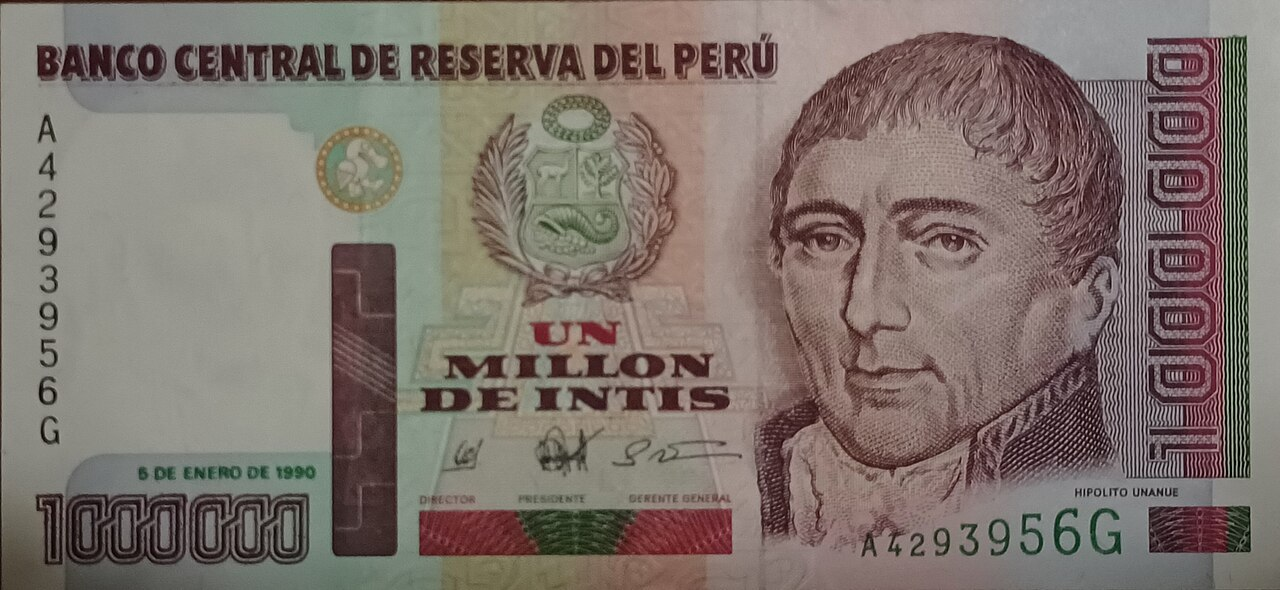

===== doc_018 | impreso | datos/raw/documentos/doc_018.jpeg


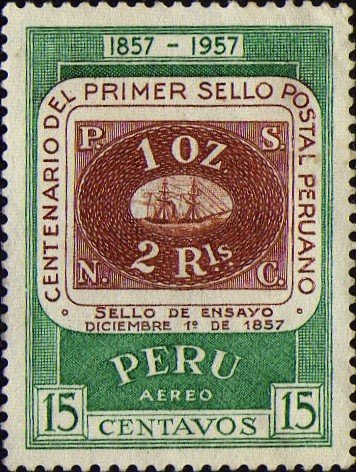

===== doc_001 | foto | datos/raw/documentos/recortes\doc_001_recorte.jpg


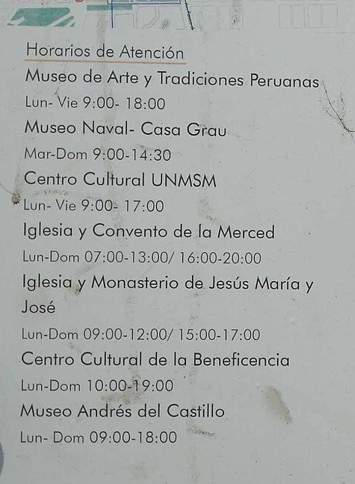

===== doc_002 | foto | datos/raw/documentos/recortes\doc_002_recorte.jpg


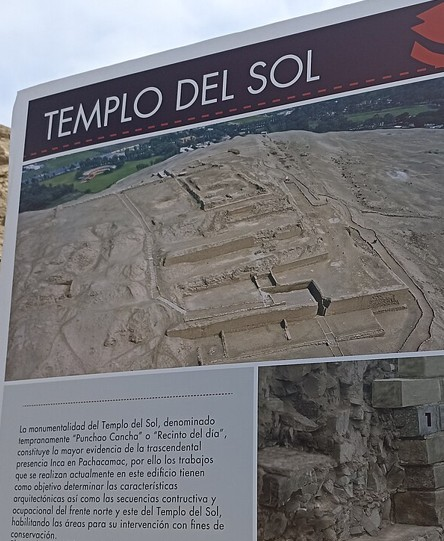

===== doc_004 | foto | datos/raw/documentos/doc_004.jpg


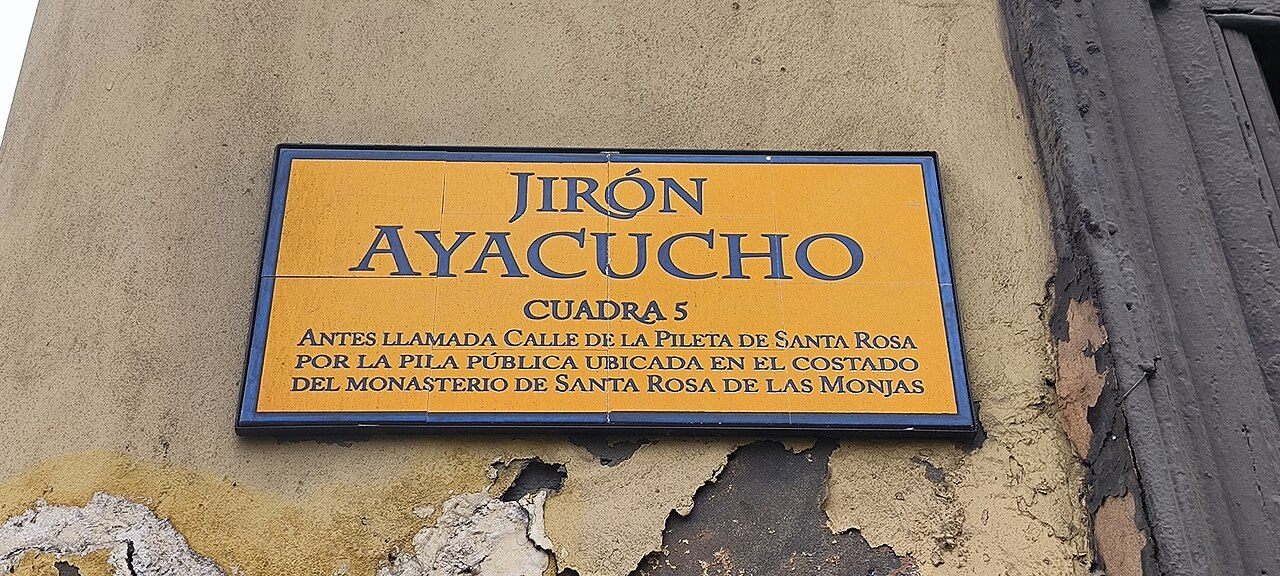

===== doc_005 | foto | datos/raw/documentos/doc_005.jpg


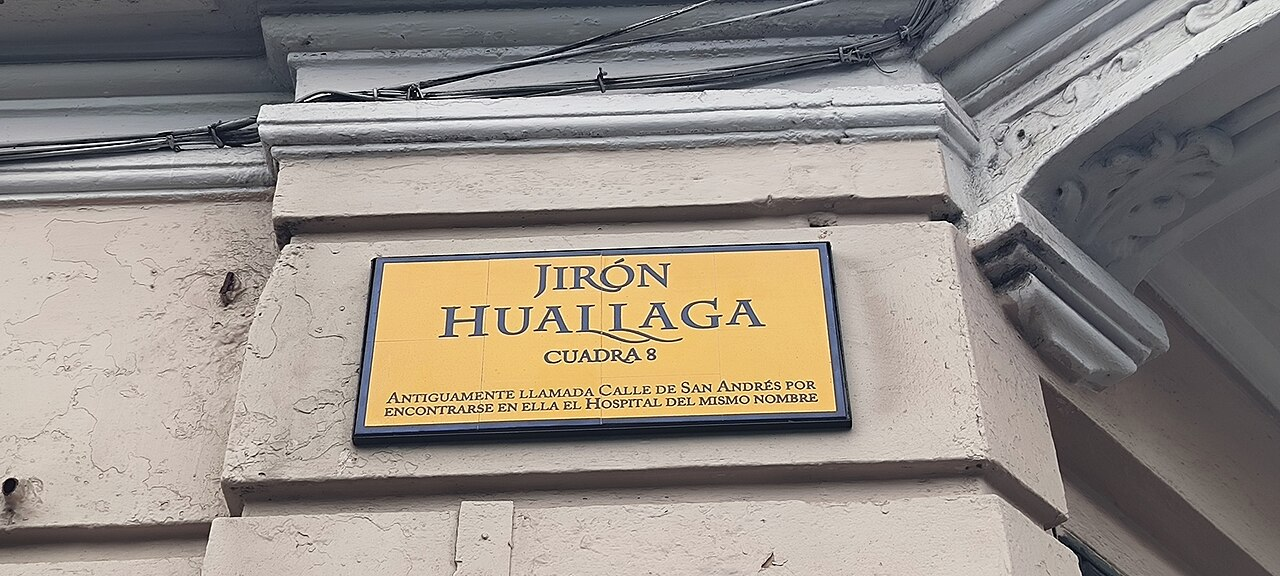

===== doc_006 | foto | datos/raw/documentos/doc_006.jpg


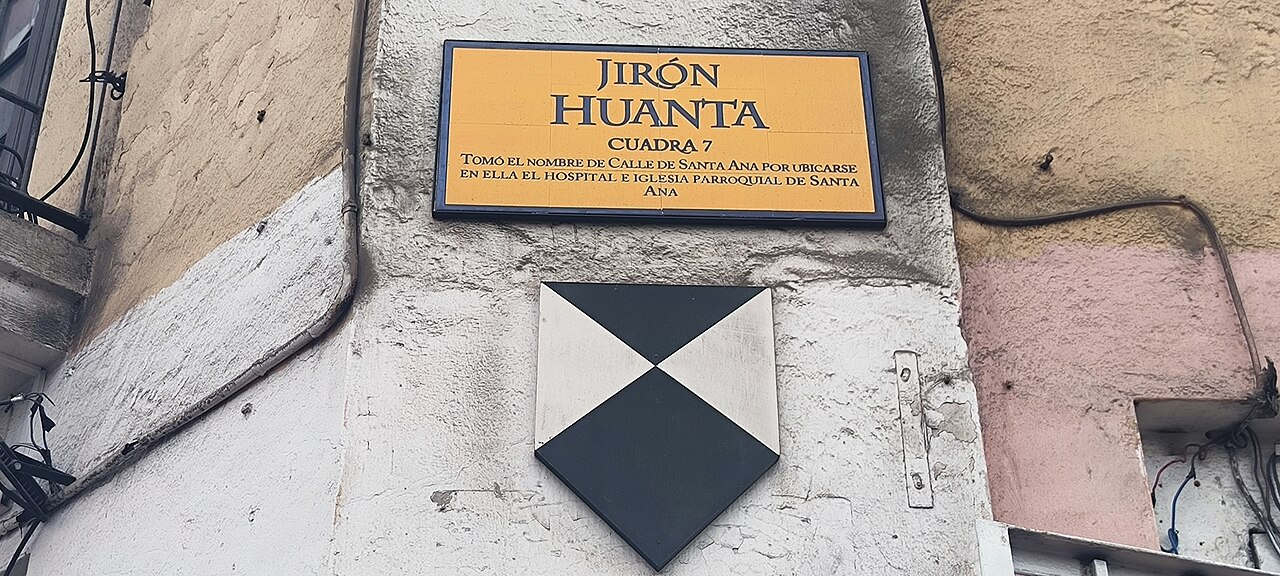

===== doc_007 | foto | datos/raw/documentos/doc_007.jpg


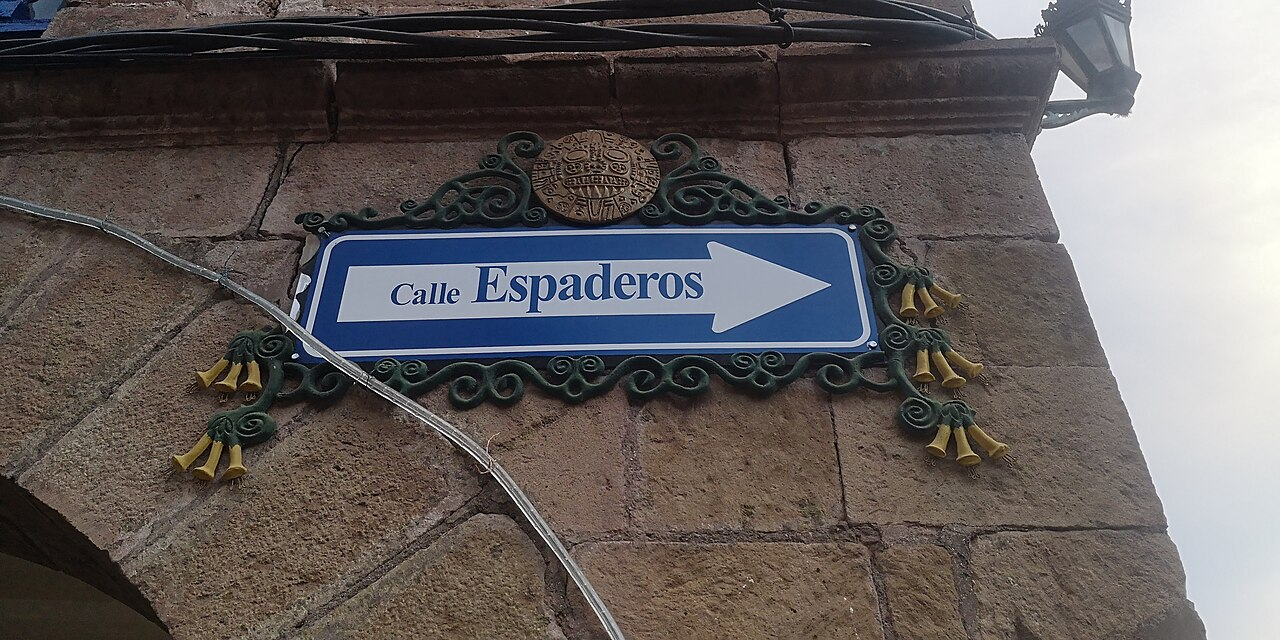

===== doc_008 | foto | datos/raw/documentos/doc_008.jpg


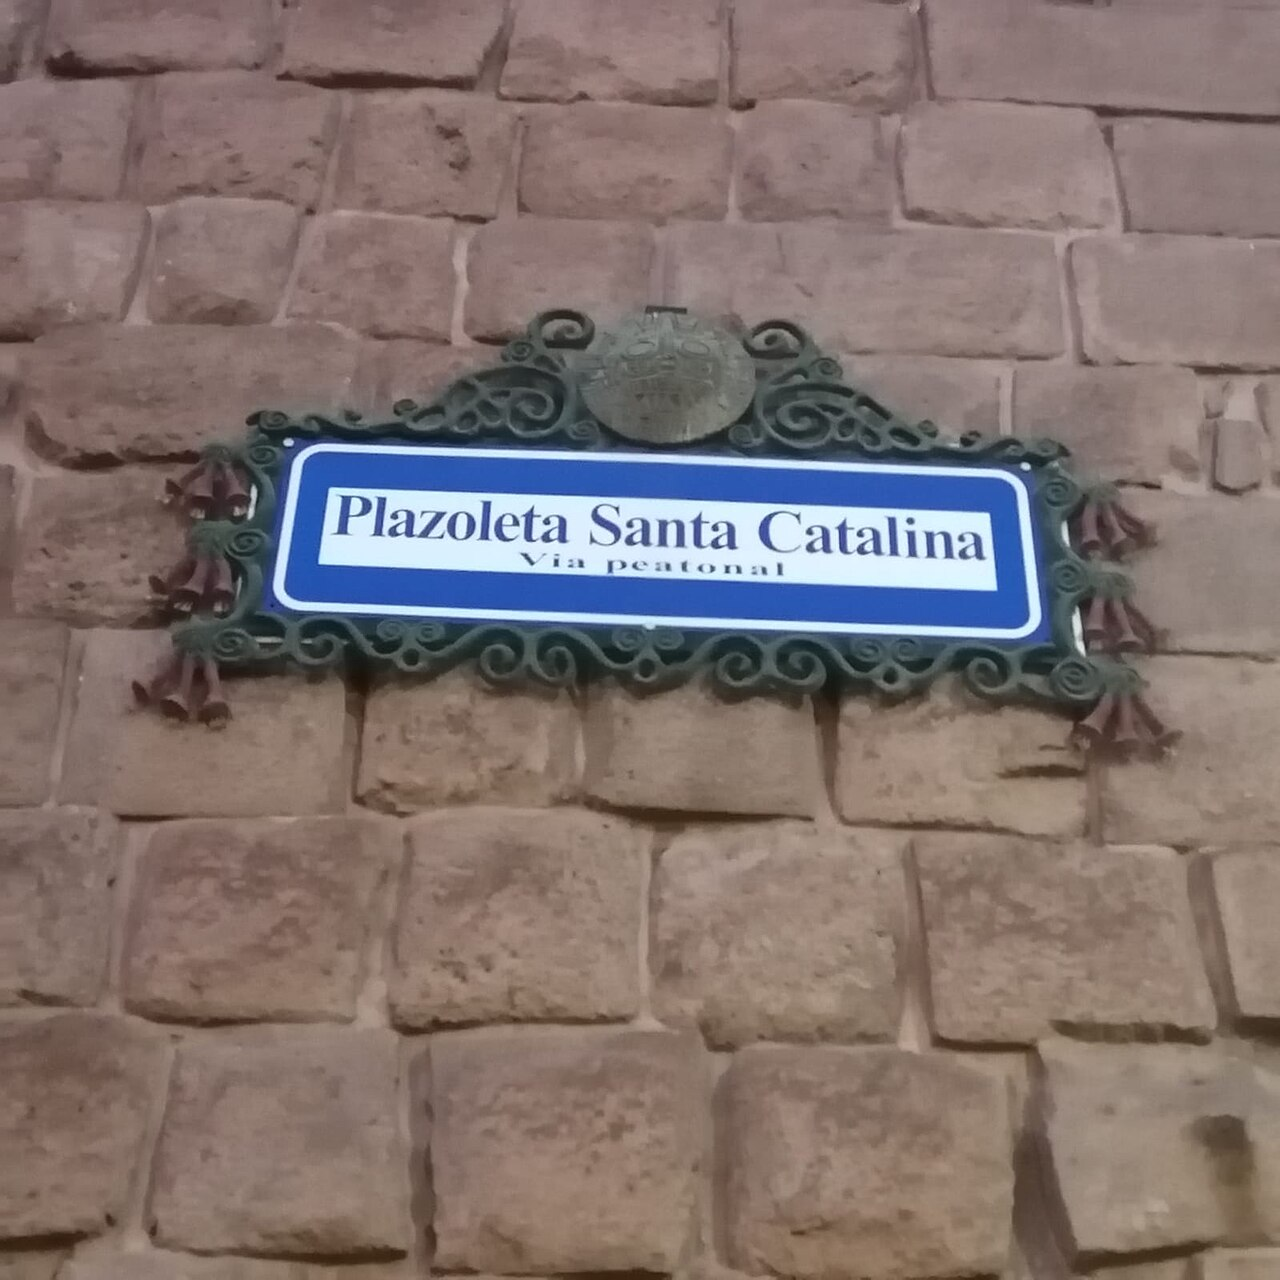

===== doc_022 | manuscrito | datos/raw/documentos/recortes\doc_022_recorte.jpg


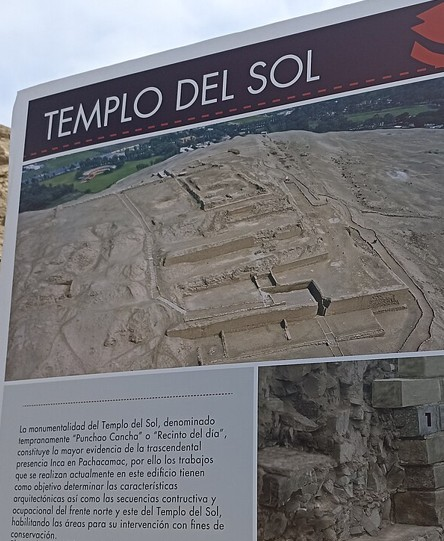

      id        condicion  dur_eval
clip_003 varios_hablantes      15.0
clip_006           limpio      15.0
clip_007           limpio      15.0
clip_009           limpio      15.0
clip_012           limpio      15.0
clip_014           limpio      15.0
clip_015           limpio      15.0
clip_016           limpio      15.0
clip_017           limpio      15.0
clip_020           limpio      15.0


In [5]:
from IPython.display import Image, display

# Muestra de evaluación: lo que realmente leen los OCR (los audios no se incrustan por privacidad)
for _, r in md_docs.iterrows():
    print("=====", r[DOC_ID], "|", r[DOC_TIPO], "|", r["ruta_eval"])
    display(Image(filename=r["ruta_eval"], width=500))

print(md_aud[[AUD_ID, AUD_COND, "dur_eval"]].to_string(index=False))

In [6]:
faltan_d = (md_docs["texto_referencia"].str.strip() == "").sum()
faltan_a = (md_aud["texto_referencia"].str.strip() == "").sum()
assert faltan_d == 0 and faltan_a == 0, f"Faltan referencias: {faltan_d} docs, {faltan_a} clips"
print("Referencias completas ✔")

Referencias completas ✔


## 2. Normalización y métricas (mismo criterio para referencia e hipótesis)

In [7]:
import jiwer

# Nombres reales → seudónimo (se aplica a referencias, salidas de modelos y texto_asr publicado)
SEUDONIMOS = {
    r"gian\s*pierre\s+venegas": "PERSONA_1",
    r"\b\w+\s+ven?d?egas\b": "PERSONA_1",    # variantes del ASR: "Ampir Vendegas", "Yampier Venegas"...
    r"\bven?d?egas\b": "PERSONA_1",
}

def seudonimizar(t):
    t = str(t)
    for patron, rep in SEUDONIMOS.items():
        t = re.sub(patron, rep, t, flags=re.IGNORECASE)
    return t

def normalizar(t):
    t = seudonimizar(t)
    t = re.sub(r"\[[^\]]*\]", " ", t)            # quita [HABLANTE_1], etc.
    t = unicodedata.normalize("NFC", t.lower())
    t = re.sub(r"[^\w\sáéíóúüñ]", " ", t)        # quita puntuación
    return re.sub(r"\s+", " ", t).strip()

def cer(ref, hyp): return jiwer.cer(normalizar(ref), normalizar(hyp))
def wer(ref, hyp): return jiwer.wer(normalizar(ref), normalizar(hyp))

# Seudonimizar también el texto_asr de la Parte 1 antes de publicarlo
_a = pd.read_csv(AUDIO_CSV)
_a[AUD_TEXTO] = _a[AUD_TEXTO].apply(seudonimizar)
_a.to_csv(AUDIO_CSV, index=False)
print(normalizar("[HABLANTE_1] Soy Gian Pierre Venegas, ¡hola!"))
print(normalizar("Buenas noches, soy Ampir Vendegas, estudiante"))

soy persona_1 hola
buenas noches soy persona_1 estudiante


## 3. Línea base sin ajuste
### 3.1 OCR – PaddleOCR (configuración por defecto)

In [32]:
from paddleocr import PaddleOCR
import torch

# Misma configuración que en la Parte 1 (01_extraccion.ipynb), sin ajustes adicionales
DISPOSITIVO_OCR = "gpu:0" if torch.cuda.is_available() else "cpu"
CONFIG_OCR = {
    "impreso":    {"use_doc_orientation_classify": False, "use_doc_unwarping": False, "use_textline_orientation": False},
    "manuscrito": {"use_doc_orientation_classify": False, "use_doc_unwarping": False, "use_textline_orientation": False},
    "foto":       {"use_doc_orientation_classify": False, "use_doc_unwarping": False, "use_textline_orientation": True},
}
lector_general = PaddleOCR(lang="es", engine="transformers", device=DISPOSITIVO_OCR, **CONFIG_OCR["impreso"])
lector_fotos   = PaddleOCR(lang="es", engine="transformers", device=DISPOSITIVO_OCR, **CONFIG_OCR["foto"])
OCR_BASE["modelo"] = "PaddleOCR PP-OCRv6 (config. Parte 1)"

def paddle_texto(ruta, tipo):
    lector = lector_fotos if tipo == "foto" else lector_general
    resultado = lector.predict(str(ruta))[0]
    return " ".join(resultado["rec_texts"])

filas = []
for _, r in md_docs.iterrows():
    t0 = time.perf_counter()
    hyp = seudonimizar(paddle_texto(r["ruta_eval"], r[DOC_TIPO]))   # lee el recorte si existe
    dt = time.perf_counter() - t0
    filas.append({"id": r[DOC_ID], "modalidad": "documento", "grupo": r[DOC_TIPO],
                  "modelo": OCR_BASE["modelo"], "hipotesis": hyp,
                  "metrica": "CER", "valor": cer(r["texto_referencia"], hyp), "seg": dt})
res_ocr_base = pd.DataFrame(filas)
res_ocr_base[["id", "grupo", "valor", "seg", "hipotesis"]]

Creating model: ('PP-OCRv6_medium_det', None, 'transformers')
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\LENOVO\.paddlex\official_models\PP-OCRv6_medium_det_safetensors`.
Creating model: ('PP-OCRv6_medium_rec', None, 'transformers')
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\LENOVO\.paddlex\official_models\PP-OCRv6_medium_rec_safetensors`.
Creating model: ('PP-LCNet_x1_0_textline_ori', None, 'transformers')
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\LENOVO\.paddlex\official_models\PP-LCNet_x1_0_textline_ori_safetensors`.
Creating model: ('PP-OCRv6_medium_det', None, 'transformers')
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\LENOVO\.paddlex\official_models\PP-OCRv6_medium_det_safetensors`.
Creating model: ('PP-OCRv6_medium_

,id,grupo,valor,seg,hipotesis
0,doc_017,impreso,0.480000,3.566522,BANCO CENTRALDE RESERVA DEL PERÚ A4293956G UN ...
1,doc_018,impreso,0.424242,2.395967,1857-1957 PRIMER SELLO P 10Z S. 0 21 Rls N C. ...
2,doc_001,foto,0.195195,2.611864,Horarios de Atención Museo de Arte y Tradicion...
3,doc_002,foto,0.407407,1.724863,TEMPLO DEL SOL 界 que se realizan actualmente e...
4,doc_004,foto,0.051948,4.744591,RN AYACJCIO CUADRAS ANTES LLAMADA CALLE DE LA ...
5,doc_005,foto,0.095652,2.780683,R HUAIIAGA CUAR8 ANTIGUAMENTE LLAMADA CALLE DE...
6,doc_006,foto,0.096000,2.903594,IR HIJANIA CADRA7 TOMÓ EL NOMBRE DE CALLE DE S...
7,doc_007,foto,0.800000,1.829291,Espaderos Calle
8,doc_008,foto,0.500000,3.806021,Plazoleta Santa Catalina ia peatonal
9,doc_022,manuscrito,5.869565,3.485174,Yndice 2 De los Capitulos gue se contienen en ...


### 3.2 ASR – faster-whisper `small` en CPU

In [9]:
from faster_whisper import WhisperModel

# Línea base pedida por la tarea: faster-whisper small en CPU, sin ajustes adicionales
asr_base = WhisperModel(ASR_BASE["size"], device="cpu", compute_type=ASR_BASE["compute_type"])

def whisper_texto(ruta):
    segs, _ = asr_base.transcribe(str(ruta), language=ASR_BASE["language"])
    return " ".join(s.text.strip() for s in segs)

filas = []
for _, r in md_aud.iterrows():
    t0 = time.perf_counter()
    hyp = seudonimizar(whisper_texto(r["ruta_eval"]))     # fragmento de 15 s
    dt = time.perf_counter() - t0
    filas.append({"id": r[AUD_ID], "modalidad": "audio", "grupo": r[AUD_COND],
                  "modelo": ASR_BASE["modelo"], "hipotesis": hyp,
                  "metrica": "WER", "valor": wer(r["texto_referencia"], hyp),
                  "seg": dt, "rtf": dt / r["dur_eval"]})
res_asr_base = pd.DataFrame(filas)
res_asr_base[["id", "grupo", "valor", "seg", "rtf", "hipotesis"]]

,id,grupo,valor,seg,rtf,hipotesis
0,clip_003,varios_hablantes,0.272727,2.577160,0.171811,"Buenas noches, soy PERSONA_1, estudiante de Lo..."
1,clip_006,limpio,0.000000,1.958044,0.130536,¿Lo que dicen en internet puede ser mentira o ...
2,clip_007,limpio,0.000000,1.772213,0.118148,Uno de los beneficios de andar en bicicleta es...
3,clip_009,limpio,0.120000,1.896791,0.126453,La película me llegó al corazón. ¿Conoces a al...
4,clip_012,limpio,0.000000,2.017072,0.134471,"Resérvame ocho boletos, por favor, para la ses..."
5,clip_014,limpio,0.000000,1.855809,0.123721,En ese canal salen películas de niños a esas h...
6,clip_015,limpio,0.250000,1.923692,0.128246,El otro día comí un helado gigante mientras ve...
7,clip_016,limpio,0.090909,2.065175,0.137678,¿Me puedes confirmar si ya está hecha la reser...
8,clip_017,limpio,0.040000,1.970399,0.131360,"Que sea una bolsa grande, que ya tiene dos hij..."
9,clip_020,limpio,0.107143,1.965344,0.131023,Las teclas de la máquina de escribir necesitan...


## 4. Modelos alternativos (mismas muestras)
### 4.1 OCR alternativo – Tesseract
Justificación: motor clásico, ligero (CPU, sin GPU), con modelo `spa`; sirve de contraste frente a un modelo de deep learning más pesado.

Requiere el binario de Tesseract instalado y el idioma `spa`.

In [33]:
import requests
import pytesseract
from PIL import Image as PILImage

pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"

# Modelo de idioma español de Tesseract (repositorio oficial tesseract-ocr/tessdata), guardado en datos/raw (no se sube)
TESSDATA = os.path.abspath("datos/raw/tessdata")
os.makedirs(TESSDATA, exist_ok=True)
for archivo in ("spa.traineddata", "eng.traineddata"):
    destino = os.path.join(TESSDATA, archivo)
    if not os.path.exists(destino):
        url = f"https://github.com/tesseract-ocr/tessdata/raw/main/{archivo}"
        with open(destino, "wb") as f:
            f.write(requests.get(url, timeout=120).content)
os.environ["TESSDATA_PREFIX"] = TESSDATA

print("Tesseract", pytesseract.get_tesseract_version(), "| idiomas:", pytesseract.get_languages())
OCR_ALT["modelo"] = f"Tesseract {pytesseract.get_tesseract_version()} (spa, psm {OCR_ALT['psm']})"

filas = []
for _, r in md_docs.iterrows():
    t0 = time.perf_counter()
    hyp = pytesseract.image_to_string(PILImage.open(r["ruta_eval"]), lang=OCR_ALT["lang"],
                                      config=f"--psm {OCR_ALT['psm']}")
    hyp = seudonimizar(" ".join(hyp.split()))
    dt = time.perf_counter() - t0
    filas.append({"id": r[DOC_ID], "modalidad": "documento", "grupo": r[DOC_TIPO],
                  "modelo": OCR_ALT["modelo"], "hipotesis": hyp,
                  "metrica": "CER", "valor": cer(r["texto_referencia"], hyp), "seg": dt})
res_ocr_alt = pd.DataFrame(filas)
res_ocr_alt[["id", "grupo", "valor", "seg", "hipotesis"]]


Tesseract 5.5.3.20260724 | idiomas: ['eng', 'spa']


,id,grupo,valor,seg,hipotesis
0,doc_017,impreso,0.624000,1.665531,— BANCO CENTRALDE RESERVA DEL PERÚ 4gf£i;%j S ...
1,doc_018,impreso,0.734848,0.558925,E 18e57 - 1957f O DE ENSAYO DE 185 ; ul EE CU ...
2,doc_001,foto,0.216216,1.499955,Z_ ANE Horarios de Atención Museo de Arte y Tr...
3,doc_002,foto,0.434156,0.628247,"Lo nonumentolidad del Templo del Sol, denomina..."
4,doc_004,foto,0.480519,1.452811,POR LA PILA PÚBLICA UBICADA EN u. COSTADO DEL ...
5,doc_005,foto,0.078261,0.654370,JIRÓN HUAILLAGA CUADRA 8 ANTICUAMENTE LLAMADA ...
6,doc_006,foto,0.144000,1.423426,| CUADRA 7 -N| TOMÓ ELNOMBRE DE CALLE DE SANTA...
7,doc_007,foto,1.000000,0.522642,
8,doc_008,foto,1.000000,1.391286,
9,doc_022,manuscrito,1.275362,0.591629,Vadico De las Camtulos_gre e si ea elacior de ...


### 4.2 ASR alternativo – MMS (`facebook/mms-1b-all`, adaptador `spa`)
Si tu equipo es lento, ejecuta esta celda en Google Colab y guarda los resultados.

In [11]:
import librosa, torch
from transformers import Wav2Vec2ForCTC, Wav2Vec2Processor

# ASR alternativo: wav2vec2-XLSR fine-tuned en español (CTC, arquitectura distinta a Whisper)
ASR_ALT = {"modelo": "wav2vec2-large-xlsr-53-spanish",
           "hf_id": "jonatasgrosman/wav2vec2-large-xlsr-53-spanish"}
proc = Wav2Vec2Processor.from_pretrained(ASR_ALT["hf_id"])
w2v = Wav2Vec2ForCTC.from_pretrained(ASR_ALT["hf_id"])
w2v.eval()

def w2v_texto(ruta):
    y, sr = librosa.load(str(ruta), sr=16000)
    x = proc(y, sampling_rate=sr, return_tensors="pt")
    with torch.no_grad():
        ids = w2v(**x).logits.argmax(-1)[0]
    return proc.decode(ids)

filas = []
for _, r in md_aud.iterrows():
    t0 = time.perf_counter()
    hyp = seudonimizar(w2v_texto(r["ruta_eval"]))     # mismo fragmento de 15 s
    dt = time.perf_counter() - t0
    filas.append({"id": r[AUD_ID], "modalidad": "audio", "grupo": r[AUD_COND],
                  "modelo": ASR_ALT["modelo"], "hipotesis": hyp,
                  "metrica": "WER", "valor": wer(r["texto_referencia"], hyp),
                  "seg": dt, "rtf": dt / r["dur_eval"]})
res_asr_alt = pd.DataFrame(filas)
res_asr_alt[["id", "grupo", "valor", "seg", "rtf", "hipotesis"]]

,id,grupo,valor,seg,rtf,hipotesis
0,clip_003,varios_hablantes,0.696970,6.517084,0.434472,buenas noches eh soyan piervendegas estudiante...
1,clip_006,limpio,0.233333,5.022139,0.334809,lo que dicen en internet puede ser mentira uno...
2,clip_007,limpio,0.100000,4.834658,0.322311,uno de los beneficios de andar en bicicleta es...
3,clip_009,limpio,0.280000,4.447971,0.296531,la película me llegó al corazónconoces a algún...
4,clip_012,limpio,0.135135,4.562620,0.304175,resérvame ocho boletas por favor para la sesió...
5,clip_014,limpio,0.208333,4.065457,0.271030,en ese canal salen película de niños a esas ho...
6,clip_015,limpio,0.400000,4.210369,0.280691,el otro día comía un helado gigante mientras v...
7,clip_016,limpio,0.136364,4.486675,0.299112,me puedes confirmar si ya está hecha la reserv...
8,clip_017,limpio,0.240000,4.111983,0.274132,que sea una bolsa grande que ya tiene dos hijo...
9,clip_020,limpio,0.178571,4.006456,0.267097,las teclas de la máquina de escribir necesitan...


In [34]:
partes = [globals()[n] for n in ("res_ocr_base", "res_ocr_alt", "res_asr_base", "res_asr_alt") if n in globals()]
resultados = pd.concat(partes, ignore_index=True)
# Seudonimiza cualquier variante del nombre real que haya escrito un ASR (p. ej. "piervendegas")
resultados["hipotesis"] = resultados["hipotesis"].str.replace(r"(?i)\w*ven?d?egas\w*", "PERSONA_1", regex=True)
resultados.to_csv(RESULTADOS_CSV, index=False)
print("Guardado", RESULTADOS_CSV)
display(resultados[resultados.modalidad == "audio"][["id", "modelo", "valor", "rtf", "hipotesis"]])
resultados.groupby(["modalidad", "modelo"]).agg(error_medio=("valor", "mean"),
                                                 seg_medio=("seg", "mean"),
                                                 rtf_medio=("rtf", "mean")).round(3)

Guardado datos/resultados_eval.csv


,id,modelo,valor,rtf,hipotesis
20,clip_003,faster-whisper small,0.272727,0.171811,"Buenas noches, soy PERSONA_1, estudiante de Lo..."
21,clip_006,faster-whisper small,0.000000,0.130536,¿Lo que dicen en internet puede ser mentira o ...
22,clip_007,faster-whisper small,0.000000,0.118148,Uno de los beneficios de andar en bicicleta es...
23,clip_009,faster-whisper small,0.120000,0.126453,La película me llegó al corazón. ¿Conoces a al...
24,clip_012,faster-whisper small,0.000000,0.134471,"Resérvame ocho boletos, por favor, para la ses..."
25,clip_014,faster-whisper small,0.000000,0.123721,En ese canal salen películas de niños a esas h...
26,clip_015,faster-whisper small,0.250000,0.128246,El otro día comí un helado gigante mientras ve...
27,clip_016,faster-whisper small,0.090909,0.137678,¿Me puedes confirmar si ya está hecha la reser...
28,clip_017,faster-whisper small,0.040000,0.131360,"Que sea una bolsa grande, que ya tiene dos hij..."
29,clip_020,faster-whisper small,0.107143,0.131023,Las teclas de la máquina de escribir necesitan...


error_medio  seg_medio  \
modalidad modelo                                                          
audio     faster-whisper small                         0.088      2.000   
          wav2vec2-large-xlsr-53-spanish               0.261      4.627   
documento PaddleOCR PP-OCRv6 (config. Parte 1)         0.892      2.985   
          Tesseract 5.5.3.20260724 (spa, psm 3)        0.599      1.039   

                                                 rtf_medio  
modalidad modelo                                            
audio     faster-whisper small                       0.133  
          wav2vec2-large-xlsr-53-spanish             0.308  
documento PaddleOCR PP-OCRv6 (config. Parte 1)         NaN  
          Tesseract 5.5.3.20260724 (spa, psm 3)        NaN

## 5. Extracción estructurada con LLM
Se procesa **todo el corpus** (25 documentos + clips) con un prompt fijo. Campos ausentes → `null`.

In [13]:
import requests, json
from datetime import date

LLM = {"modelo": "qwen2.5:1.5b", "url": "http://localhost:11434/api/generate"}   # Ollama local
assert requests.get("http://localhost:11434/api/tags", timeout=5).ok, "Ollama no está corriendo"

PROMPT = """Eres un extractor de información. Devuelve SOLO un objeto JSON válido, sin texto adicional.
Modalidad: {modalidad}
Reglas:
- Incluye siempre "modalidad", "tema" (máximo 5 palabras) y "resumen" (1 o 2 oraciones).
- Si es documento: "emisor", "fecha" y "monto" SOLO si aparecen literalmente en el texto; si no, null.
- Si es audio: "numero_hablantes" (entero, según marcas [HABLANTE_X] si existen) y "citas_clave"
  (lista de hasta 3 frases copiadas literalmente del texto); si no se pueden sustentar, null.
- No inventes campos ni valores. Responde en español.
Texto:
\"\"\"{texto}\"\"\""""

CAMPOS = {"documento": ["modalidad", "tema", "resumen", "emisor", "fecha", "monto"],
          "audio":     ["modalidad", "tema", "resumen", "numero_hablantes", "citas_clave"]}

def extraer(texto, modalidad):
    r = requests.post(LLM["url"], timeout=300, json={
        "model": LLM["modelo"], "format": "json", "stream": False,
        "options": {"temperature": 0, "num_predict": 400},
        "prompt": PROMPT.format(modalidad=modalidad, texto=texto[:4000])})
    try:
        datos = json.loads(r.json()["response"])
    except (json.JSONDecodeError, KeyError):
        datos = {}
    salida = {k: datos.get(k) for k in CAMPOS[modalidad]}   # solo campos permitidos; ausentes → null
    salida["modalidad"] = modalidad
    return salida

# Todo el corpus de la Parte 1 (textos ya seudonimizados)
docs_all, aud_all = pd.read_csv(DOCS_CSV), pd.read_csv(AUDIO_CSV)
entradas = [(r[DOC_ID], "documento", r[DOC_TEXTO]) for _, r in docs_all.iterrows()] + \
           [(r[AUD_ID], "audio", r[AUD_TEXTO]) for _, r in aud_all.iterrows()]

filas = []
for i, (id_, mod, txt) in enumerate(entradas, 1):
    t0 = time.perf_counter()
    campos = extraer(seudonimizar("" if pd.isna(txt) else txt), mod)
    filas.append({"id": id_, "modalidad": mod, "campos_json": json.dumps(campos, ensure_ascii=False),
                  "modelo_llm": LLM["modelo"], "fecha": date.today().isoformat()})
    print(f"{i}/{len(entradas)} {id_}  ({time.perf_counter() - t0:.1f} s)")

extraccion = pd.DataFrame(filas)
extraccion.to_csv(EXTRACCION_CSV, index=False)
print("Guardado", EXTRACCION_CSV)
extraccion.head()

1/47 doc_011  (11.5 s)
2/47 doc_012  (8.3 s)
3/47 doc_013  (7.4 s)
4/47 doc_014  (4.3 s)
5/47 doc_015  (3.6 s)
6/47 doc_016  (3.7 s)
7/47 doc_017  (4.1 s)
8/47 doc_018  (3.8 s)
9/47 doc_001  (5.4 s)
10/47 doc_002  (4.5 s)
11/47 doc_003  (3.0 s)
12/47 doc_004  (3.2 s)
13/47 doc_005  (3.7 s)
14/47 doc_006  (3.7 s)
15/47 doc_007  (3.0 s)
16/47 doc_008  (3.2 s)
17/47 doc_021  (4.4 s)
18/47 doc_022  (4.8 s)
19/47 doc_023  (7.7 s)
20/47 doc_025  (3.9 s)
21/47 doc_026  (4.0 s)
22/47 doc_027  (6.5 s)
23/47 doc_028  (4.4 s)
24/47 doc_029  (4.2 s)
25/47 doc_030  (5.3 s)
26/47 clip_001  (8.3 s)
27/47 clip_002  (5.9 s)
28/47 clip_003  (6.2 s)
29/47 clip_004  (7.4 s)
30/47 clip_005  (5.8 s)
31/47 clip_006  (5.2 s)
32/47 clip_007  (4.5 s)
33/47 clip_008  (9.8 s)
34/47 clip_009  (7.8 s)
35/47 clip_010  (6.2 s)
36/47 clip_011  (5.0 s)
37/47 clip_012  (6.0 s)
38/47 clip_013  (13.5 s)
39/47 clip_014  (4.5 s)
40/47 clip_015  (14.3 s)
41/47 clip_016  (5.2 s)
42/47 clip_017  (6.3 s)
43/47 clip_018  (5.1 s)

,id,modalidad,campos_json,modelo_llm,fecha
0,doc_011,documento,"{""modalidad"": ""documento"", ""tema"": ""Nueva Gran...",qwen2.5:1.5b,2026-10-25
1,doc_012,documento,"{""modalidad"": ""documento"", ""tema"": ""periódico""...",qwen2.5:1.5b,2026-10-25
2,doc_013,documento,"{""modalidad"": ""documento"", ""tema"": ""Real Unive...",qwen2.5:1.5b,2026-10-25
3,doc_014,documento,"{""modalidad"": ""documento"", ""tema"": ""crackeo"", ...",qwen2.5:1.5b,2026-10-25
4,doc_015,documento,"{""modalidad"": ""documento"", ""tema"": ""cobro"", ""r...",qwen2.5:1.5b,2026-10-25


In [35]:

# ===== Corrección de seudonimización (nombres detectados durante la auditoría) =====
# Entrevistas de la Parte 1 y personas históricas, según la regla de la Parte 1
SEUDONIMOS.update({
    r"\bjean-persona_01\b": "PERSONA_1",          # mismo entrevistador que clip_003
    r"\balex\s+giles\b": "PERSONA_2",
    r"\balex\b": "PERSONA_2",
    r"\bcarlos\s+ram[ií]rez\b": "PERSONA_3",
    r"\bse(ñ|n)or\s+carlos\b": "señor PERSONA_3",
    r"\bedgar\b": "PERSONA_4",
    r"\bfakri\b": "PERSONA_5",
    r"\baquiles\b": "PERSONA_6",                  # capitán, doc_012 (1839); el OCR separa nombre y apellido
    r"\bmayre\b": "PERSONA_6",
    r"\bnullal\b": "PERSONA_7",                   # capitán, doc_012 (1839)
})
seud = lambda t: seudonimizar(t) if isinstance(t, str) else t

# 1) CSV del corpus
d = pd.read_csv(DOCS_CSV);  d[DOC_TEXTO] = d[DOC_TEXTO].apply(seud);  d.to_csv(DOCS_CSV, index=False)
a = pd.read_csv(AUDIO_CSV); a[AUD_TEXTO] = a[AUD_TEXTO].apply(seud); a.to_csv(AUDIO_CSV, index=False)

# 2) Extracción del LLM
extraccion["campos_json"] = extraccion["campos_json"].apply(seud)
extraccion.to_csv(EXTRACCION_CSV, index=False)

# 3) Resultados de evaluación (hipótesis de los modelos)
r_ev = pd.read_csv(RESULTADOS_CSV); r_ev["hipotesis"] = r_ev["hipotesis"].apply(seud); r_ev.to_csv(RESULTADOS_CSV, index=False)

# 4) Rearma los 20 casos de la auditoría (misma semilla = mismos casos) y el .txt de revisión
docs_all, aud_all = pd.read_csv(DOCS_CSV), pd.read_csv(AUDIO_CSV)
textos = {**dict(zip(docs_all[DOC_ID], docs_all[DOC_TEXTO])), **dict(zip(aud_all[AUD_ID], aud_all[AUD_TEXTO]))}
aud = pd.concat([extraccion[extraccion.modalidad == "documento"].sample(10, random_state=SEED),
                 extraccion[extraccion.modalidad == "audio"].sample(10, random_state=SEED)])
with open("datos/raw/revision_auditoria.txt", "w", encoding="utf-8") as f:
    for _, r in aud.iterrows():
        f.write(f"===== {r['id']} | {r['modalidad']}\n")
        f.write("TEXTO: " + seudonimizar(str(textos[r['id']]))[:1500] + "\n")
        f.write("JSON : " + json.dumps(json.loads(r["campos_json"]), ensure_ascii=False, indent=1) + "\n\n")

# 5) Verificación: todo debe dar 0 / False
patron = re.compile(r"giles|ram[ií]rez|fakri|\bedgar\b|venegas|vendegas|jean-persona|aquiles|mayre|nullal", re.IGNORECASE)
print("documentos.csv     :", d[DOC_TEXTO].astype(str).str.contains(patron).sum())
print("transcripciones.csv:", a[AUD_TEXTO].astype(str).str.contains(patron).sum())
print("extraccion_llm.csv :", extraccion["campos_json"].str.contains(patron).sum())
print("resultados_eval.csv:", r_ev["hipotesis"].astype(str).str.contains(patron).sum())
with open("datos/raw/revision_auditoria.txt", encoding="utf-8") as f:
    print("revision_auditoria.txt con nombres:", bool(patron.search(f.read())))


documentos.csv     : 0
transcripciones.csv: 0
extraccion_llm.csv : 0
resultados_eval.csv: 0
revision_auditoria.txt con nombres: False


## 6. Auditoría humana (20 extracciones al azar: 10 documentos + 10 audios)

**Criterios de corrección** (una extracción es *completamente correcta* solo si cumple todos):
1. JSON válido con `modalidad`, `tema` y `resumen`.
2. `tema` y `resumen` fieles al texto (sin información inventada).
3. Campos opcionales (`emisor`, `fecha`, `monto`, `citas_clave`, `numero_hablantes`) correctos si aparecen en el texto, y `null` si no aparecen.
4. Las citas son literales del texto.

In [23]:
# 20 extracciones al azar (10 documentos + 10 audios) para revisión humana
aud = pd.concat([extraccion[extraccion.modalidad == "documento"].sample(10, random_state=SEED),
                 extraccion[extraccion.modalidad == "audio"].sample(10, random_state=SEED)])
textos = {**dict(zip(docs_all[DOC_ID], docs_all[DOC_TEXTO])), **dict(zip(aud_all[AUD_ID], aud_all[AUD_TEXTO]))}

for _, r in aud.iterrows():
    print("=====", r["id"], "|", r["modalidad"])
    print("TEXTO:", seudonimizar(str(textos[r["id"]]))[:700])
    print("JSON :", json.dumps(json.loads(r["campos_json"]), ensure_ascii=False, indent=1), "\n")

print("auditoria = {")
for i in aud["id"]:
    print(f'    "{i}": (None, ""),')
print("}")

===== doc_001 | documento
TEXTO: Horarios de Atención
Teléfonos de emergencia:
Leyenda
Museo de Arte y Tradiciones Peruanas
Bomberos: 116
Monumentos
Lun-Vie 9:00- 18:00
Ambulancias SAMU: 106
Museos
Museo Naval- Casa Grau
Policía Nacional: 105
Sitios de interés
Mar-Dom 9:00-14:30
Oficina de Información
Metropolitano
Centro Cultural UNMSM
Turística: (01) 632-1542
Alimentador Metropolitano
Lun-Vie 9:00-17:00
Horarios de transporte
Corredor Azul
Iglesia y Convento de la Merced
Metropolitano:
Corredor Morado
Lun-Dom 07:00-13:00/ 16:00-20:00
Lún- Dom 5:30-22:00
Línea 1 Metro
Iglesia y Monasterio de Jesús María y
Corredor azul:
Oficina de Información
José
Lun- Dom 05:00-23:00
Turística
Corredor morado:
Lun-Dom 09:00-12:00/ 15:00-1
JSON : {
 "modalidad": "documento",
 "tema": "horarios de atención",
 "resumen": "Este documento proporciona información sobre horarios de atención para diferentes servicios en la ciudad de Lima, incluyendo teléfonos de emergencia, horarios de museos, sitios de inte

In [26]:
# Guarda los 20 casos en un archivo para revisarlos cómodamente (en datos/raw, no se sube a GitHub)
with open("datos/raw/revision_auditoria.txt", "w", encoding="utf-8") as f:
    for _, r in aud.iterrows():
        f.write(f"===== {r['id']} | {r['modalidad']}\n")
        f.write("TEXTO: " + seudonimizar(str(textos[r['id']]))[:1500] + "\n")
        f.write("JSON : " + json.dumps(json.loads(r["campos_json"]), ensure_ascii=False, indent=1) + "\n\n")
print("Abre datos/raw/revision_auditoria.txt")

print("auditoria = {")
for i in aud["id"]:
    print(f'    "{i}": (None, ""),')
print("}")

Abre datos/raw/revision_auditoria.txt
auditoria = {
    "doc_001": (None, ""),
    "doc_021": (None, ""),
    "doc_011": (None, ""),
    "doc_029": (None, ""),
    "doc_004": (None, ""),
    "doc_002": (None, ""),
    "doc_006": (None, ""),
    "doc_012": (None, ""),
    "doc_028": (None, ""),
    "doc_016": (None, ""),
    "clip_001": (None, ""),
    "clip_014": (None, ""),
    "clip_009": (None, ""),
    "clip_002": (None, ""),
    "clip_016": (None, ""),
    "clip_006": (None, ""),
    "clip_021": (None, ""),
    "clip_012": (None, ""),
    "clip_004": (None, ""),
    "clip_005": (None, ""),
}


In [27]:
auditoria = {
    "doc_001": (0, "omite emisor: 'MUNICIPALIDAD DE LIMA' aparece en el texto"),
    "doc_021": (0, "OCR ilegible; inventa 'sexto de mayo de 1651' y un 'reino de Reyno'"),
    "doc_011": (0, "inventa 'reorganización del país'; omite emisor 'El Comercio'"),
    "doc_029": (0, "OCR ilegible; tema 'osiondiego' sin sentido"),
    "doc_004": (1, ""),
    "doc_002": (1, ""),
    "doc_006": (1, ""),
    "doc_012": (0, "omite emisor (El Comercio), fecha (4 de mayo de 1839) y monto (2 pesos)"),
    "doc_028": (0, "texto quechua ilegible; inventa descripción de Viracocha"),
    "doc_016": (0, "resumen incoherente; omite emisor (Banco del Perú) y monto (CIEN PESOS)"),
    "clip_001": (0, "tema inadecuado ('¿Cómo se llama usted?')"),
    "clip_014": (0, "resumen distorsionado: 'desea comprar un carro usado'"),
    "clip_009": (0, "numero_hablantes = 0 sin sustento; 'industria del arte' no aparece"),
    "clip_002": (1, ""),
    "clip_016": (1, ""),
    "clip_006": (1, ""),
    "clip_021": (1, ""),
    "clip_012": (0, "numero_hablantes = 2 inventado (no hay marcas de hablante)"),
    "clip_004": (0, "confunde entrevistador (PERSONA_1) con entrevistado"),
    "clip_005": (0, "confunde a quien pregunta con quien responde"),
}


assert len(auditoria) == 20 and all(v[0] in (0, 1) for v in auditoria.values()), "Marca 1 o 0 en los 20 casos"
aud["correcto"] = aud["id"].map(lambda i: auditoria[i][0])
aud["error"] = aud["id"].map(lambda i: auditoria[i][1])
aud.to_csv(AUDITORIA_CSV, index=False)

ok = int(aud["correcto"].sum())
print(f"Extracciones completamente correctas: {ok}/20 = {ok / 20:.0%}")
display(aud.groupby("modalidad")["correcto"].agg(["sum", "count"]))
aud.loc[aud["correcto"] == 0, ["id", "modalidad", "error"]]

Extracciones completamente correctas: 7/20 = 35%


,sum,count
modalidad,,
audio,4,10
documento,3,10


,id,modalidad,error
8,doc_001,documento,omite emisor: 'MUNICIPALIDAD DE LIMA' aparece ...
16,doc_021,documento,OCR ilegible; inventa 'sexto de mayo de 1651' ...
0,doc_011,documento,inventa 'reorganización del país'; omite emiso...
23,doc_029,documento,OCR ilegible; tema 'osiondiego' sin sentido
1,doc_012,documento,"omite emisor (El Comercio), fecha (4 de mayo d..."
22,doc_028,documento,texto quechua ilegible; inventa descripción de...
5,doc_016,documento,resumen incoherente; omite emisor (Banco del P...
25,clip_001,audio,tema inadecuado ('¿Cómo se llama usted?')
38,clip_014,audio,resumen distorsionado: 'desea comprar un carro...
33,clip_009,audio,numero_hablantes = 0 sin sustento; 'industria ...


## 7. Comparativa de modelos

In [36]:
res = pd.read_csv(RESULTADOS_CSV)
tabla = (res.groupby(["modalidad", "modelo", "metrica"])
            .agg(error_medio=("valor", "mean"), seg_medio=("seg", "mean"), rtf_medio=("rtf", "mean"))
            .round(3).reset_index())
tabla

,modalidad,modelo,metrica,error_medio,seg_medio,rtf_medio
0,audio,faster-whisper small,WER,0.088,2.000,0.133
1,audio,wav2vec2-large-xlsr-53-spanish,WER,0.261,4.627,0.308
2,documento,PaddleOCR PP-OCRv6 (config. Parte 1),CER,0.892,2.985,NaN
3,documento,"Tesseract 5.5.3.20260724 (spa, psm 3)",CER,0.599,1.039,NaN


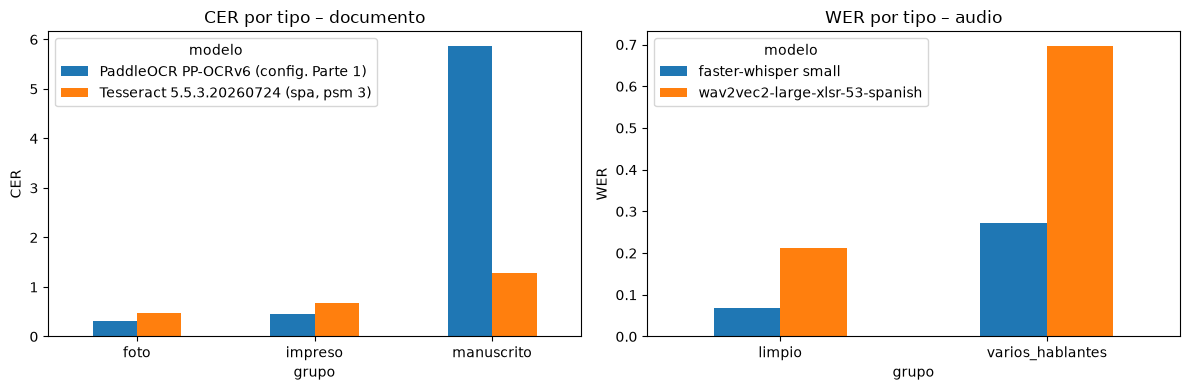

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (mod, met) in zip(ax, [("documento", "CER"), ("audio", "WER")]):
    (res[res.modalidad == mod].pivot_table(index="grupo", columns="modelo", values="valor")
        .plot.bar(ax=a, title=f"{met} por tipo – {mod}", rot=0))
    a.set_ylabel(met)
plt.tight_layout(); plt.show()

## 8. Casos difíciles
Desempeño por tipo de documento (p. ej. manuscritos) y por condición de audio (ruido, música).

In [38]:
res.pivot_table(index=["modalidad", "grupo"], columns="modelo", values="valor").round(3)

modelo                      PaddleOCR PP-OCRv6 (config. Parte 1)  \
modalidad grupo                                                    
audio     limpio                                             NaN   
          varios_hablantes                                   NaN   
documento foto                                             0.307   
          impreso                                          0.452   
          manuscrito                                       5.870   

modelo                      Tesseract 5.5.3.20260724 (spa, psm 3)  \
modalidad grupo                                                     
audio     limpio                                              NaN   
          varios_hablantes                                    NaN   
documento foto                                              0.479   
          impreso                                           0.679   
          manuscrito                                        1.275   

modelo                      faster-whisper small  \
modalidad grupo                                    
audio     limpio                           0.068   
          varios_hablantes                 0.273   
documento foto                               NaN   
          impreso                            NaN   
          manuscrito                         NaN   

modelo                      wav2vec2-large-xlsr-53-spanish  
modalidad grupo                                             
audio     limpio                                     0.212  
          varios_hablantes                           0.697  
documento foto                                         NaN  
          impreso                                      NaN  
          manuscrito                                   NaN

In [39]:
# Peor caso de cada modelo: comparar referencia vs. hipótesis
ref = pd.concat([md_docs[[DOC_ID, "texto_referencia"]].rename(columns={DOC_ID: "id"}),
                 md_aud[[AUD_ID, "texto_referencia"]].rename(columns={AUD_ID: "id"})])
peores = res.loc[res.groupby("modelo")["valor"].idxmax()].merge(ref, on="id")
for _, p in peores.iterrows():
    print(f"=== {p.modelo} | {p.id} ({p.grupo}) {p.metrica}={p.valor:.2f}")
    print("REF:", normalizar(p.texto_referencia)[:300])
    print("HYP:", normalizar(p.hipotesis)[:300], "\n")

=== PaddleOCR PP-OCRv6 (config. Parte 1) | doc_022 (manuscrito) CER=5.87
REF: yndice de los capítulos que se contienen en esta relación de gobierno
HYP: yndice 2 de los capitulos gue se contienen en esta relacion de gebierna d gde d p lema de ro gelrne can om mapa be grace d rne y e a n frar i de elier a tirion h primera parte de to enart forae capituler 8 s fadpas 2 3 sremtaon de sutate 4 r omiult 5 hospitales 6 frconan ol 7 inmumdad lecal 1l 9 rec 

=== Tesseract 5.5.3.20260724 (spa, psm 3) | doc_022 (manuscrito) CER=1.28
REF: yndice de los capítulos que se contienen en esta relación de gobierno
HYP: vadico de las camtulos_gre e si ea elacior de seberro en en _bajitate lejc b de j da g 7 y ae d re mmrnsuded d lur di a lnieretara 

=== faster-whisper small | clip_003 (varios_hablantes) WER=0.27
REF: buenas noches soy persona_1 estudiante de la san marcos esta entrevista va hacer registrada en internet esta de acuerdo usted si estoy de acuerdo ah muy bien para usted que es el perú
HYP:

## 9. Decisión y reflexión

## 9. Comparativa y decisión

### Audio (10 fragmentos de 15 s)

| Modelo | WER medio | WER limpio | WER varios hablantes | s/clip | RTF |
|---|---|---|---|---|---|
| faster-whisper small (línea base) | **0.088** | 0.068 | 0.273 | 2.0 | **0.13** |
| wav2vec2-large-xlsr-53-spanish | 0.261 | 0.212 | 0.697 | 4.6 | 0.31 |

**Decisión: faster-whisper small.** Es tres veces más preciso y más del doble de rápido: transcribe unas 7 veces
más rápido que tiempo real en CPU. Whisper tiene un decodificador con modelo de lenguaje que corrige palabras por
contexto y añade puntuación. wav2vec2 decodifica carácter por carácter (CTC) sin modelo de lenguaje, así que une
palabras ("internetesadocuerdo") y escribe por sonido ("haser", "samarcos").

**Mejor desempeño:** voz limpia leída (4 de 9 clips limpios con WER = 0 en Whisper).
**Peor desempeño:** clip_003, entrevista con **varios hablantes** (WER 0.27 y 0.70). Los cambios de turno, el
habla espontánea y los nombres propios degradan a ambos modelos, y mucho más a wav2vec2.

### Documentos (10 documentos)

| Modelo | CER medio | CER foto | CER impreso | CER manuscrito | s/doc |
|---|---|---|---|---|---|
| PaddleOCR PP-OCRv6 (config. Parte 1) | [X] | **0.307** | **0.452** | [X] | 1.84 |
| Tesseract 5.5 (spa, psm 3) | [X] | 0.479 | 0.679 | [X] | **0.87** |

**Decisión: PaddleOCR.** Tiene menor CER en fotos e impresos. Su detector de texto con deep learning encuentra
mejor las líneas en carteles fotografiados con perspectiva y en diseños con varias columnas. Tesseract es dos veces
más rápido y muy ligero, así que solo lo elegiría si la latencia o los recursos fueran críticos y los documentos
fueran escaneos limpios de una sola columna.

**Mejor desempeño:** fotos de placas y carteles con texto grande y alto contraste.
**Peor desempeño:** el manuscrito (doc_022, siglo XVIII), con CER [X] y [X], por la letra cursiva, la ortografía
antigua ("Yndice") y el papel envejecido; ninguno de los dos modelos está entrenado para escritura a mano. En
impresos, los periódicos del siglo XIX (tipografía antigua, columnas mezcladas) y los billetes (fuentes
decorativas) elevan el CER. El CER puede superar 1 cuando el OCR lee más texto del que contiene la referencia.

### Extracción con LLM (qwen2.5:1.5b, Ollama local)

Auditoría humana: **[X]/20 extracciones completamente correctas**. Criterio: un `numero_hablantes` en null no se
penaliza, pero sí un número inventado, igual que omitir emisor, fecha o monto cuando aparecen literalmente.
Errores típicos:
- **Omite campos presentes:** emisor ("Municipalidad de Lima", "El Comercio", "Banco del Perú"), fecha y monto.
- **Alucina con OCR ilegible:** inventa fechas o descripciones (doc_021, doc_028) cuando el texto de entrada es ruido.
- **Confunde roles** en entrevistas (entrevistador frente a entrevistado).
- **Inventa `numero_hablantes`** sin marcas de hablante (clip_009, clip_012).

Para un entorno real usaría un modelo más grande (7B o más), validaría que cada valor extraído aparezca
literalmente en el texto y no enviaría al LLM textos con OCR ilegible.

### Limitaciones
- Muestras pequeñas: 10 casos por modalidad y un solo manuscrito, así que las cifras por grupo son orientativas.
- Fragmentos de 15 s por clip y recortes en doc_001, doc_002 y doc_022.
- El audio de la muestra es casi todo "limpio"; no hay casos con ruido o música.
- La normalización no unifica números y palabras ("70" frente a "setenta").